# D8. 추론 최적화 & Streaming ASR: faster-whisper · 양자화 · whisper.cpp · 청크 스트리밍

**음성 AI 전문가 과정 (160h) | 2주차 M2 | 4시간**

## 학습 목표
1. Whisper가 **어디서 시간을 쓰는지**(30초 창 패딩 · Decoder 반복 · 프레임워크 오버헤드)를 직접 재고, 줄이는 도구를 짝지을 수 있다.
2. **faster-whisper**(CTranslate2 엔진)로 같은 모델을 더 빠르게 돌리고, 결과가 **'게으른 생성기(generator)'** 로 나온다는 점을 이해한다.
3. **양자화**(float16 · int8)의 원리를 직접 구현해 보고, `compute_type`에 따른 속도 · 메모리 · 정확도 변화를 비교한다.
4. **VAD**와 **배치 처리**(BatchedInferencePipeline)로 긴 녹음을 몇 배 빠르게 처리한다.
5. **whisper.cpp**를 직접 빌드하고, 모델을 **q5_0으로 양자화**해 GPU 없이 C++ 실행 파일로 받아 적는다.
6. 마이크 소리를 흉내 낸 **청크 스트리밍**을 만들고, **LocalAgreement**로 '확정된 글자'를 띄우며 **지연(latency)** 을 잰다.

## 오늘의 실습 흐름
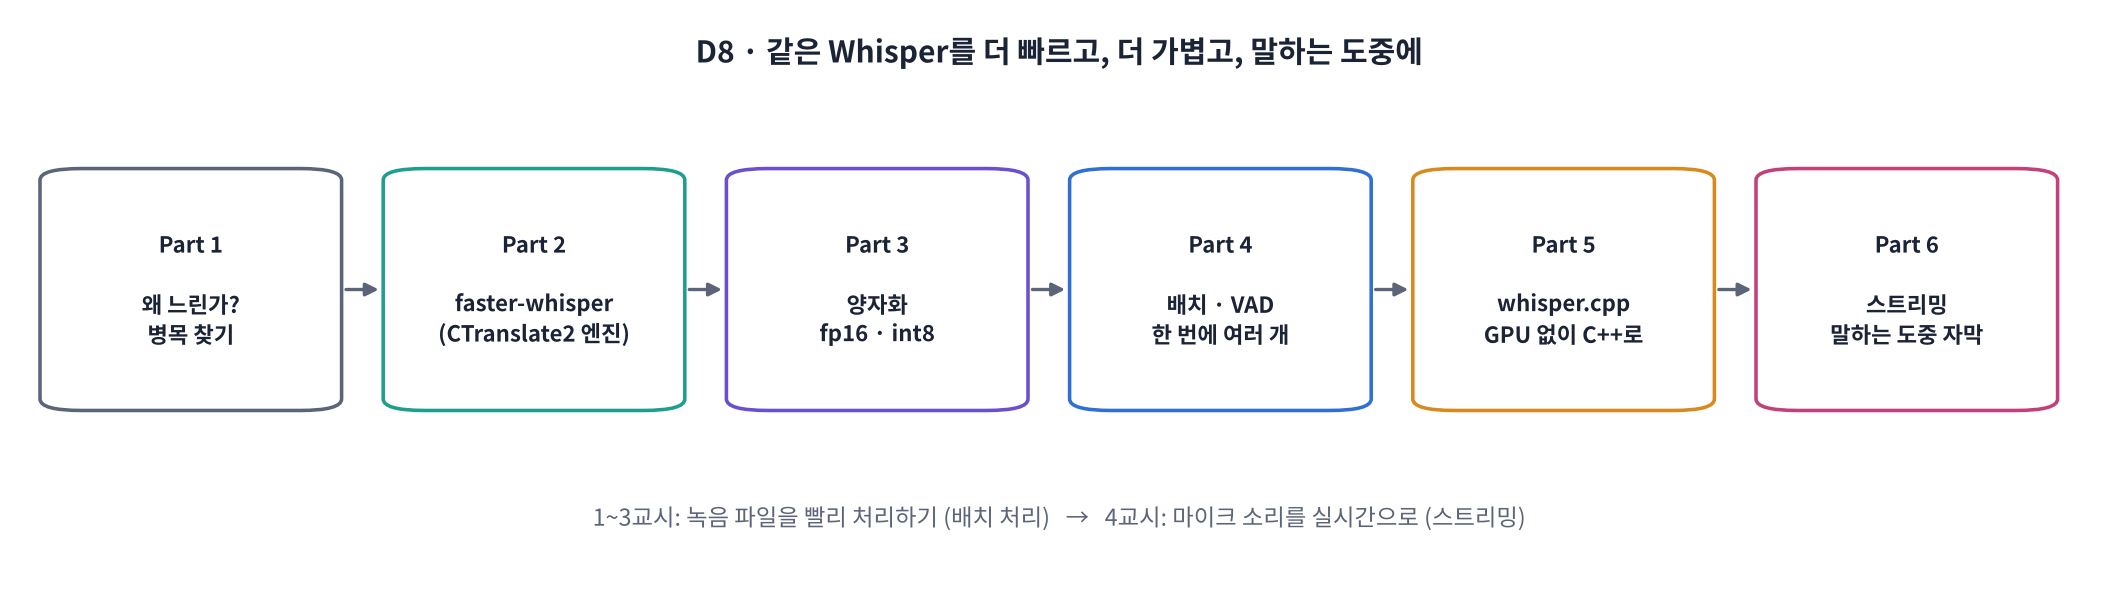

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | 왜 느린가(병목 재기), faster-whisper, 게으른 생성기 | Part 0 ~ 2, 워크시트 1교시 |
| 2교시 | 양자화 원리와 `compute_type` 비교, VAD · 배치 처리 | Part 3 ~ 4, 워크시트 2교시 |
| 3교시 | whisper.cpp 빌드 · ggml 모델 · q5_0 양자화 · CLI 실행 | Part 5, 워크시트 3교시 |
| 4교시 | 스트리밍: 고정 청크의 문제, LocalAgreement, 지연 측정 | Part 6 ~ 7, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day08/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day08/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 셀은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- D7처럼 **수식보다 그림과 말로** 설명합니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 필요한 식 하나와 "읽는 법" |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🔍 **코드 해설** | 주요 코드를 한 줄씩 |

> ⚙️ **T4 GPU 런타임을 권장합니다** ([런타임] → [런타임 유형 변경] → **T4 GPU**). CPU에서도 끝까지 돌아가지만(자동으로 `int8` · 짧은 비교만) 2교시의 GPU 배치 효과는 보이지 않습니다. 3교시 whisper.cpp는 **일부러 CPU로** 돌립니다.

> 🎬 **애니메이션 D8-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#flow) — Part 1~6 로드맵

## Part 0. 준비

**faster-whisper**(CTranslate2 엔진 포함), 시험 음성용 **gTTS**, 글자 오류율 **jiwer**, VAD용 **silero-vad**를 설치합니다. `transformers` · `torch`는 Colab에 이미 있습니다.

In [ ]:
!pip install -q faster-whisper gTTS jiwer silero-vad
print("✅ 설치 완료")

In [ ]:
import os, time, re, subprocess, shutil
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import torch
import jiwer
from IPython.display import Audio, display
from gtts import gTTS

SR = 16000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def norm(s):
    # 비교 전에 문장 부호와 띄어쓰기를 지워 '글자'만 비교 (D7과 같음)
    return re.sub(r"[\s.,!?'\"·~-]", "", s).lower()

def sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

print(f"torch {torch.__version__} | device = {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else " (CPU 모드)") + f" | CPU 코어 {os.cpu_count()}개")

In [ ]:
# 오늘의 시험 음성: 강의처럼 이어지는 문장 6개 (gTTS) + 중간에 6초 무음
def tts(text, path, lang="ko"):
    gTTS(text, lang=lang).save(path)
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=35)
    return y.astype(np.float32)

SENTS = [
    "안녕하세요. 오늘은 위스퍼를 빠르게 만드는 방법을 배웁니다.",
    "아이구루 교육센터에서 라이브킷과 파이프캣으로 음성 에이전트를 만듭니다.",
    "양자화를 하면 모델 크기가 줄어들고 속도가 빨라집니다.",
    "배치 처리는 여러 구간을 한꺼번에 계산하는 방법입니다.",
    "스트리밍 인식은 말하는 도중에 자막을 보여 줍니다.",
    "지연 시간이 짧을수록 대화가 자연스러워집니다.",
]
clips = [tts(s, f"s{i}.mp3") for i, s in enumerate(SENTS)]
gap = np.zeros(int(0.5 * SR), dtype=np.float32)
quiet = (0.002 * np.random.default_rng(1).standard_normal(6 * SR)).astype(np.float32)   # 6초 거의 무음

story = np.concatenate([x for c in clips[:3] for x in (c, gap)])                       # 짧은 이야기 (스트리밍용)
lecture = np.concatenate([clips[0], gap, clips[1], gap, clips[2], quiet, clips[3], gap, clips[4], gap, clips[5]])
REF_STORY = " ".join(SENTS[:3]); REF_LECTURE = " ".join(SENTS)
print(f"문장 {len(clips)}개, 짧은 이야기 {len(story) / SR:.1f}초, 강의 녹음 {len(lecture) / SR:.1f}초")
display(Audio(lecture, rate=SR))

## Part 1. 왜 느린가: 시간이 어디로 가는지 재기

> 💬 **쉽게 말하면**: 최적화의 첫걸음은 **재는 것**입니다. 어디서 시간이 새는지 알아야 맞는 도구를 고를 수 있습니다. D7에서 본 Whisper의 약점 두 가지(30초 창, Decoder 반복)가 실제로 얼마나 큰지 먼저 잽니다.

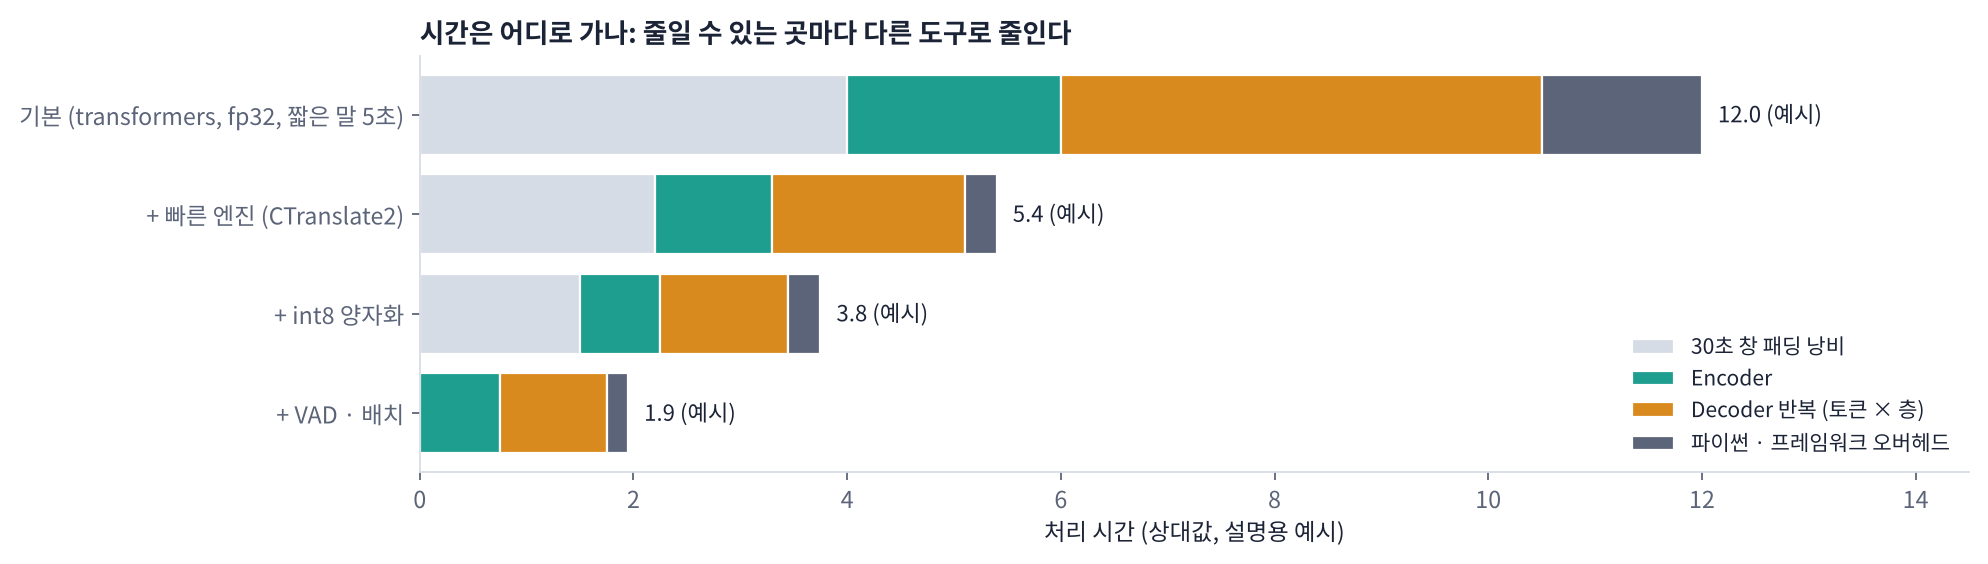

| 시간이 새는 곳 | 왜 | 오늘의 도구 |
|---|---|---|
| **30초 창 패딩** | 3초 말도 30초만큼 계산 (D7) | **VAD**로 말만 넣기 · 짧은 구간을 **배치**로 묶기 (Part 4) |
| **Decoder 반복** | 토큰 하나 쓸 때마다 Decoder 전체를 다시 돌림 (D6 · D7) | **빠른 엔진** (Part 2), **turbo**처럼 Decoder가 작은 모델 |
| **숫자가 큼** | 가중치 하나에 4바이트(float32) | **양자화** float16 · int8 (Part 3) |
| **파이썬 · 프레임워크 오버헤드** | 작은 연산마다 파이썬이 GPU에 일을 시킴 | **C++ 엔진**: CTranslate2 (Part 2), whisper.cpp (Part 5) |

> 🍎 **비유: 택배 배송 시간 줄이기**. 트럭이 반쯤 빈 채 다니면(패딩) 짐을 모아 싣고(배치), 같은 동네를 여러 번 오가면(Decoder 반복) 경로를 줄이고, 짐이 크면(float32) 압축 포장하고(양자화), 서류 처리가 느리면(파이썬) 자동화 창구(C++ 엔진)로 바꿉니다. **어디가 막혔는지 모르고 트럭만 바꾸면 소용없습니다.**

> 🎬 **애니메이션 D8-2:** [병목 찾기](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#bottleneck) — 최적화를 하나씩 켜며 시간 막대가 줄어드는 모습

In [ ]:
# 기준선(baseline): D7과 같은 transformers + whisper-small, 기본 float32
from transformers import WhisperProcessor, WhisperForConditionalGeneration

MAIN = "openai/whisper-small"
proc = WhisperProcessor.from_pretrained(MAIN)
hf = WhisperForConditionalGeneration.from_pretrained(MAIN).to(DEVICE).eval()     # 아무 최적화 없는 기본값

def hf_transcribe(y):
    f = proc(y, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = hf.generate(f, language="ko")
    return proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

hf_transcribe(clips[0])                                          # 워밍업
sync(); t0 = time.time()
hyps = [hf_transcribe(c) for c in clips]
sync(); t_hf = time.time() - t0
dur_clips = sum(len(c) for c in clips) / SR
cer_hf = jiwer.cer([norm(s) for s in SENTS], [norm(h) for h in hyps])
print(f"transformers float32 | 문장 {len(clips)}개 ({dur_clips:.1f}초) → {t_hf:.2f}초 | RTF {t_hf / dur_clips:.3f} | CER {cer_hf:.1%}")
print("예:", hyps[1])

### 🧩 빈칸 실습 1: Encoder와 Decoder 중 누가 더 오래 걸리나
짧은 문장 하나를 받아 적는 **전체 시간**과 **Encoder만의 시간**을 쟀습니다. 나머지가 Decoder(토큰을 한 개씩 반복 생성) 몫입니다.

In [ ]:
# 🧩 빈칸 실습 1
y = clips[1]
f = proc(y, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
with torch.no_grad():
    hf.model.encoder(f); sync()                                   # 워밍업
    t0 = time.time(); hf.model.encoder(f); sync(); enc_time = time.time() - t0
    t0 = time.time(); ids = hf.generate(f, language="ko"); sync(); total = time.time() - t0

dec_time = total - ____
n_tok = ids.shape[1] - 4                                          # 특수 토큰 4개 제외
print(f"전체 {total * 1000:6.0f} ms = Encoder {enc_time * 1000:5.0f} ms + Decoder {dec_time * 1000:6.0f} ms (토큰 {n_tok}개)")
print(f"Decoder 몫 {dec_time / total:.0%} → 토큰 하나당 약 {dec_time / max(n_tok, 1) * 1000:.0f} ms")

plt.figure(figsize=(9, 1.6))
plt.barh([0], [enc_time * 1000], color="tab:cyan", label="Encoder (once)")
plt.barh([0], [dec_time * 1000], left=[enc_time * 1000], color="tab:orange", label=f"Decoder ({n_tok} tokens)")
plt.yticks([]); plt.xlabel("ms"); plt.legend(loc="upper right"); plt.title("where does the time go? (one 5-second sentence)"); plt.tight_layout(); plt.show()
check(abs(enc_time + dec_time - total) < 1e-9 and dec_time > 0, hint="전체에서 Encoder 시간을 빼면 Decoder 몫입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
dec_time = total - enc_time
```

**해설**: 짧은 문장에서는 보통 **Decoder가 절반 이상**을 씁니다. Encoder는 한 번만 돌지만, Decoder는 토큰 수(수십 개)만큼 반복해서 돌기 때문입니다. 그래서 Decoder를 4층으로 줄인 **turbo**가 빠르고, 반복 하나하나를 빠르게 만드는 **C++ 엔진**이 효과가 큽니다.

</details>

## Part 2. faster-whisper: 같은 모델, 더 빠른 엔진

> 💬 **쉽게 말하면**: faster-whisper는 Whisper를 새로 만든 것이 아니라, **같은 가중치를 CTranslate2라는 C++ 추론 엔진에서 돌리는 것**입니다. 정확도는 같고, 속도는 최대 약 4배, 메모리는 더 적게 씁니다(공개 자료 기준).

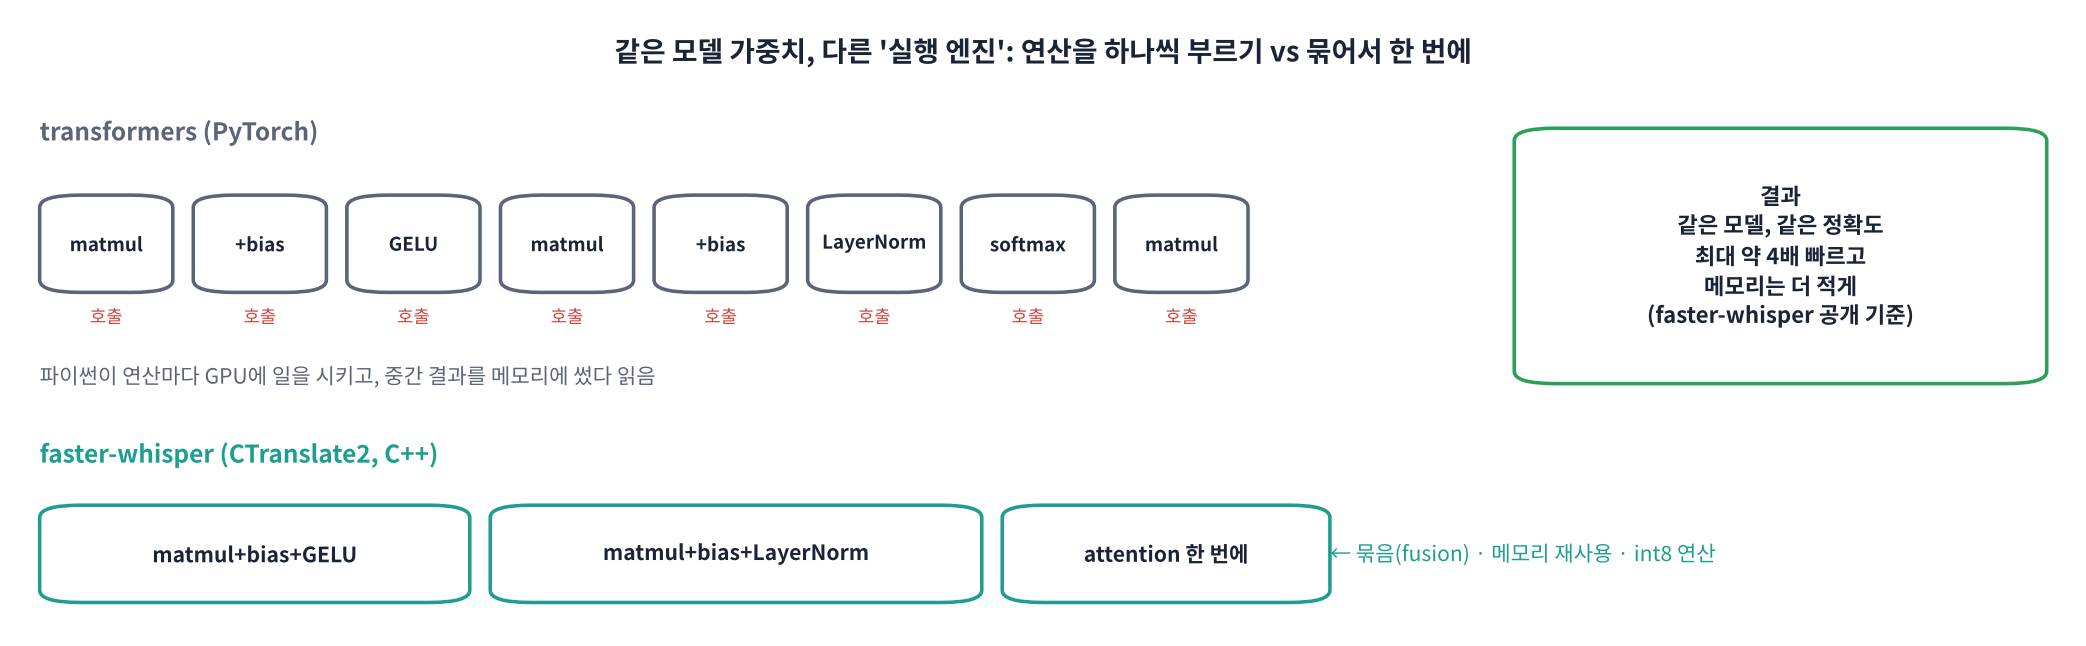

👣 **한 단계씩: 왜 빨라질까**
1. **파이썬을 거치지 않음**: transformers는 연산 하나마다 파이썬이 GPU에 일을 시킵니다. CTranslate2는 C++ 안에서 쭉 돌립니다.
2. **연산 묶기(fusion)**: "곱하기 → 더하기 → 활성화"처럼 이어지는 연산을 한 번에 계산해서, 중간 결과를 메모리에 썼다 읽는 일을 줄입니다.
3. **int8 · float16 연산**: 숫자를 작게 저장하고 계산합니다 (Part 3).
4. **Decoder 반복을 위한 최적화**: 이전 토큰의 계산을 재사용(KV 캐시)하고 빔 서치를 엔진 안에서 처리합니다.

> 🍎 **비유: 같은 요리사, 다른 주방**. 레시피(가중치)와 요리사(모델)는 같은데, 재료를 미리 손질해 두고 동선을 줄인 주방(엔진)으로 옮긴 것입니다. 음식 맛(정확도)은 같고 나오는 시간이 빨라집니다.

모델 이름 `"small"`을 주면 **이미 CTranslate2 형식으로 변환해 둔 모델**(Hugging Face `Systran/faster-whisper-small`)을 내려받습니다. 직접 변환하려면 `ct2-transformers-converter` 명령을 씁니다.

> 🎬 **애니메이션 D8-3:** [실행 엔진 비교](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#engine) — 연산을 하나씩 부르는 엔진과 묶어서 부르는 엔진의 시간 비교

In [ ]:
from faster_whisper import WhisperModel

CT = "float16" if DEVICE == "cuda" else "int8"                   # GPU는 반정밀도, CPU는 int8이 가장 빠름
fw = WhisperModel("small", device=DEVICE, compute_type=CT)
print(f"faster-whisper small 로드 완료 (device={DEVICE}, compute_type={CT})")

### 2-1. 게으른 생성기(generator): 결과는 '꺼낼 때' 계산된다

> 💬 **쉽게 말하면**: `fw.transcribe()`는 바로 받아 적지 않고 **'받아 적을 준비가 된 목록'(generator)** 만 돌려줍니다. `for`로 꺼내거나 `list()`로 감싸는 순간에야 실제 계산이 일어납니다.

👣 **한 단계씩**
1. `segments, info = fw.transcribe(y)` → 언어 감지 정도만 하고 즉시 돌아옴. `segments`는 아직 비어 있는 약속
2. `for s in segments:` → 30초 창을 하나 처리할 때마다 구간(segment)이 하나씩 나옴
3. 그래서 **시간을 잴 때는 반드시 `list()`까지 포함**해야 합니다. 안 그러면 '0.01초 만에 끝났다'는 착각을 합니다.

> 🍎 **비유: 회전 초밥**. 주문서(`transcribe`)를 내자마자 '접수됐습니다' 소리는 바로 들리지만, 초밥은 접시를 꺼낼 때마다 하나씩 나옵니다. 장점도 있습니다. **긴 녹음이면 첫 구간 결과를 먼저 화면에 보여 줄 수 있습니다.**

### 🧩 빈칸 실습 2: 생성기를 목록으로 꺼내기
`segments`를 **목록으로 바꾸는** 파이썬 내장 함수를 넣으세요. 시간이 얼마나 달라지는지 보세요.

In [ ]:
# 🧩 빈칸 실습 2
t0 = time.time()
segments, info = fw.transcribe(lecture, language="ko", beam_size=1)
t_call = time.time() - t0                                         # transcribe() 호출만

t0 = time.time()
segs = ____(segments)                                             # 여기서 실제로 받아 적음
t_list = time.time() - t0

print(f"transcribe() 호출: {t_call:.3f}초 → list()로 꺼내기: {t_list:.2f}초  (진짜 일은 여기서!)")
print(f"언어 {info.language}, 음성 길이 {info.duration:.1f}초, 구간 {len(segs)}개")
for s in segs:
    print(f"[{s.start:6.2f} → {s.end:6.2f}] {s.text.strip()}")
fw_text = " ".join(s.text.strip() for s in segs)
print(f"\nCER {jiwer.cer(norm(REF_LECTURE), norm(fw_text)):.1%} | RTF {(t_call + t_list) / info.duration:.3f}")
check(isinstance(segs, list) and t_list > t_call, hint="파이썬 내장 함수 list 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
segs = list(segments)
```

**해설**: `list()`가 생성기를 끝까지 돌려 구간을 모두 꺼냅니다. 호출 자체는 거의 0초, `list()`에서 대부분의 시간이 걸린 것을 확인하세요. `for s in segments: print(s.text)`처럼 쓰면 **구간이 나오는 대로 바로 출력**되어, 긴 파일에서도 사용자가 기다리는 느낌이 줄어듭니다. 단, 생성기는 **한 번만** 꺼낼 수 있습니다. 두 번 쓰려면 `list()`로 저장해 두세요.

</details>

In [ ]:
# ▶️ 비교: transformers vs faster-whisper (같은 small, 같은 greedy, 같은 문장 6개)
fw.transcribe(clips[0], language="ko", beam_size=1)               # 생성기라서 이것만으로는 받아 적지 않음
list(fw.transcribe(clips[0], language="ko", beam_size=1)[0])      # 진짜 워밍업
sync(); t0 = time.time()
fw_hyps = [" ".join(s.text.strip() for s in fw.transcribe(c, language="ko", beam_size=1)[0]) for c in clips]
sync(); t_fw = time.time() - t0
cer_fw = jiwer.cer([norm(s) for s in SENTS], [norm(h) for h in fw_hyps])

rows = [("transformers float32", t_hf, cer_hf), (f"faster-whisper {CT}", t_fw, cer_fw)]
for n, t, c in rows:
    print(f"{n:24s} | {t:6.2f}초 | RTF {t / dur_clips:.3f} | CER {c:6.1%}")
print(f"→ {t_hf / t_fw:.1f}배 빠름")
plt.figure(figsize=(7, 2)); plt.barh([r[0] for r in rows], [r[1] for r in rows], color=["gray", "tab:cyan"])
plt.xlabel("seconds for 6 sentences"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

#### 🔍 코드 해설: faster-whisper 기본 사용법

| 코드 | 하는 일 |
|---|---|
| `WhisperModel("small", device="cuda", compute_type="float16")` | 변환된 모델을 내려받아 GPU에 올림. 이름 대신 로컬 폴더 경로도 가능 |
| `fw.transcribe(y, language="ko", beam_size=1)` | `(segments 생성기, info)`를 돌려줌. 넘파이 배열(16 kHz) 또는 파일 경로 |
| `beam_size` | **기본값 5** (D7의 Whisper 원본 CLI와 같음). 오늘 비교에서는 transformers와 맞추려고 1 |
| `info.language`, `info.language_probability` | 언어 감지 결과 (D7 Part 3) |
| `s.start`, `s.end`, `s.text` | 구간 시작 · 끝(초)과 문장 |
| `s.avg_logprob`, `s.no_speech_prob`, `s.compression_ratio` | D7의 환각 검사 값이 **구간마다 그대로 들어 있음** |

**❓ 생각해 보기**: faster-whisper의 transcribe()는 D7에서 배운 안전장치(temperature fallback, 압축률 2.4, logprob −1.0, 무음 0.6)를 기본으로 쓸까요?

<details>
<summary>답 보기</summary>

네. faster-whisper는 Whisper 원본의 `transcribe()` 동작을 따라 **기본값으로 temperature 사다리(0.0~1.0), compression_ratio_threshold=2.4, log_prob_threshold=−1.0, no_speech_threshold=0.6** 을 씁니다. 텍스트(글자)를 압축하므로 기준도 원본과 같은 2.4입니다. transformers에서 1.35를 썼던 것과 비교해 보세요.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day08/worksheet.html)** — 병목 네 가지와 도구 짝짓기, Encoder 한 번 vs Decoder 반복, RTF, CTranslate2가 빠른 이유(파이썬 오버헤드 · 연산 묶기 · KV 캐시), 같은 가중치 · 같은 정확도, 게으른 생성기와 `list()`, 기본 beam 5
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 3. 양자화: 숫자를 작게 저장하기

> 💬 **쉽게 말하면**: 모델의 가중치(약 2억 4천만 개의 숫자)를 **더 적은 비트로** 저장합니다. float32(4바이트) → float16(2바이트) → int8(1바이트). 크기와 메모리가 2배, 4배 줄고, 하드웨어가 지원하면 계산도 빨라집니다. 대가는 **아주 약간의 정확도**입니다.

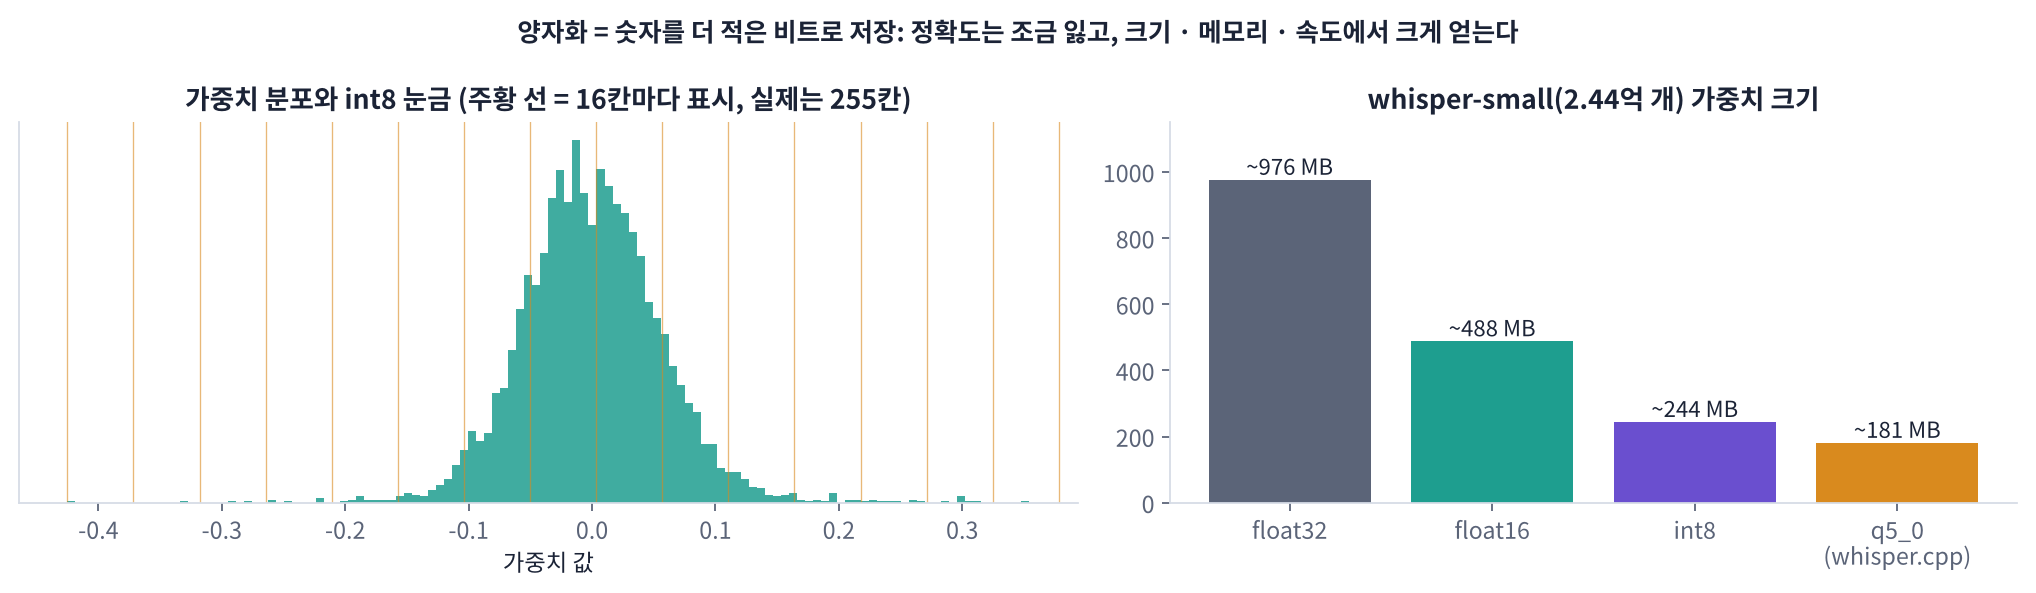

### 3-1. int8 양자화는 이렇게 한다

👣 **한 단계씩** (가중치 묶음 하나에 대해)
1. 가장 큰 절댓값을 찾습니다: 예) 0.38
2. 그 값을 127(int8의 가장 큰 양수)에 맞추는 **눈금 간격(scale)** 을 정합니다: 0.38 ÷ 127 ≈ 0.003
3. 각 가중치를 눈금 간격으로 나누고 **반올림** → −127 ~ 127의 정수로 저장
4. 계산할 때는 정수 × 눈금 간격으로 되돌립니다 (원래 값과 조금 다름 = 양자화 오차)

📐 **핵심 식 하나**

$$q = \text{round}\left(\frac{w}{\text{scale}}\right), \qquad \text{scale} = \frac{\max |w|}{127}, \qquad \hat w = q \times \text{scale}$$

**읽는 법**: 자로 길이를 잴 때 mm 눈금(float32) 대신 cm 눈금(int8)만 있는 자를 쓰는 것입니다. 255칸짜리 자로 재니 끝자리가 조금 틀리지만, 신경망은 수많은 가중치를 더하는 과정에서 이런 작은 오차가 서로 상쇄되어 결과가 거의 변하지 않습니다.

> 🍎 **비유: 사진 압축**. 원본 사진(RAW, float32)을 JPEG(int8)로 저장하면 크기는 몇 분의 1인데, 눈으로 보기엔 거의 같습니다. 너무 세게 압축하면(4비트, 2비트) 그때부터 티가 납니다.

> 🎬 **애니메이션 D8-4:** [양자화 눈금](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#quant) — 비트 수를 16 → 8 → 4로 줄이며 눈금이 성글어지고 오차가 커지는 모습

### 🧩 빈칸 실습 3: int8 양자화 직접 구현
기준선 모델(transformers)의 Decoder 첫 층 가중치 하나를 int8로 바꿔 봅니다. 가중치를 **무엇으로 나눠야** 정수 눈금이 될까요?

In [ ]:
# 🧩 빈칸 실습 3
w = hf.model.decoder.layers[0].fc1.weight.detach().float().cpu()       # (3072, 768) 가중치 하나
scale = w.abs().max() / 127                                             # 눈금 간격 (한 덩어리 전체에 하나)
q = torch.round(w / ____).clamp(-127, 127).to(torch.int8)               # int8 정수로
w_hat = q.float() * scale                                               # 되돌리기

err = (w - w_hat).abs()
print(f"가중치 모양 {tuple(w.shape)}, 개수 {w.numel():,}")
print(f"눈금 간격 scale = {scale.item():.6f}")
print(f"원래  : {w[0, :5].numpy().round(5)}")
print(f"정수 q: {q[0, :5].numpy()}")
print(f"복원  : {w_hat[0, :5].numpy().round(5)}")
print(f"평균 오차 {err.mean().item():.2e} (가중치 평균 크기 {w.abs().mean().item():.2e}의 {err.mean().item() / w.abs().mean().item():.1%})")
print(f"메모리: float32 {w.numel() * 4 / 1e6:.1f} MB → int8 {q.numel() / 1e6:.1f} MB")

fig, axs = plt.subplots(1, 2, figsize=(12, 2.8))
axs[0].hist(w.flatten().numpy(), bins=200, color="tab:cyan"); axs[0].set_title("original weights (float32)")
axs[1].hist((w - w_hat).flatten().numpy(), bins=200, color="tab:orange"); axs[1].set_title("quantization error (w - w_hat)")
plt.tight_layout(); plt.show()
check(q.dtype == torch.int8 and err.max().item() <= scale.item() / 2 + 1e-6, hint="눈금 간격 scale로 나눕니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
q = torch.round(w / scale).clamp(-127, 127).to(torch.int8)
```

**해설**: 반올림 오차는 **최대 눈금 간격의 절반**을 넘지 않습니다(check에서 확인). 실제 엔진은 이 방식을 조금 더 똑똑하게 씁니다. 행(출력 채널)마다 따로 scale을 두어(per-channel) 큰 값 하나 때문에 눈금이 성글어지는 것을 막습니다. 오차 히스토그램이 0 근처에 좁게 모여 있는 것을 보세요.

</details>

### 🧩 빈칸 실습 4: 숫자 형식별 모델 크기
숫자 하나에 몇 바이트를 쓰는지 채우고, whisper-small 가중치가 형식마다 몇 MB인지 계산하세요.

In [ ]:
# 🧩 빈칸 실습 4
BYTES = {"float32": 4, "float16": 2, "int8": ____}

n_params = sum(p.numel() for p in hf.parameters())
print(f"whisper-small 파라미터 {n_params / 1e6:.0f}M 개")
for k, b in BYTES.items():
    print(f"  {k:8s}: 숫자 하나 {b}바이트 → 가중치 약 {n_params * b / 1e6:5.0f} MB")
check(BYTES["int8"] * 8 == 8 and n_params * BYTES["float32"] / (n_params * BYTES["int8"]) == 4, hint="int8 = 8비트 = 몇 바이트?")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
BYTES = {"float32": 4, "float16": 2, "int8": 1}
```

**해설**: 8비트 = 1바이트입니다. 그래서 int8은 float32의 **4분의 1**입니다. 실제 GPU 메모리는 가중치 외에 Encoder 출력 · KV 캐시 · 빔 후보 등도 쓰므로 이보다 조금 더 듭니다.

</details>

### 3-2. faster-whisper의 `compute_type` 비교

| compute_type | 가중치 저장 | 계산 | 어디서 |
|---|---|---|---|
| `float32` | 4바이트 | float32 | CPU 기본 (가장 느림) |
| `float16` | 2바이트 | float16 | **GPU 기본**. 정확도 거의 그대로 |
| `int8_float16` | 1바이트 | 일부 int8, 나머지 float16 | GPU, 메모리를 아끼고 싶을 때 |
| `int8` | 1바이트 | int8 | **CPU에서 가장 빠름**. GPU에서도 가능 |

> ⚠️ **"작을수록 항상 빠르다"는 아닙니다.** 하드웨어가 int8 계산을 잘 지원해야 빨라집니다. T4 GPU는 float16이 매우 빨라서 int8이 오히려 비슷하거나 느릴 수도 있습니다. 그래서 **직접 재 봐야** 합니다.

In [ ]:
# ▶️ 비교: compute_type별 속도와 정확도 (같은 small, 문장 6개)
TYPES = ["float16", "int8_float16", "int8"] if DEVICE == "cuda" else ["float32", "int8"]
qrows = []
for ct in TYPES:
    m = WhisperModel("small", device=DEVICE, compute_type=ct)
    list(m.transcribe(clips[0], language="ko", beam_size=1)[0])           # 워밍업
    sync(); t0 = time.time()
    hyps_q = [" ".join(s.text.strip() for s in m.transcribe(c, language="ko", beam_size=1)[0]) for c in clips]
    sync(); t = time.time() - t0
    c = jiwer.cer([norm(s) for s in SENTS], [norm(h) for h in hyps_q])
    qrows.append((ct, t, c)); print(f"{ct:13s} | {t:6.2f}초 | RTF {t / dur_clips:.3f} | CER {c:6.1%}")
    del m

fig, ax = plt.subplots(1, 2, figsize=(11, 2.6))
ax[0].bar([r[0] for r in qrows], [r[1] for r in qrows], color="tab:purple"); ax[0].set_title("seconds (lower = faster)")
ax[1].bar([r[0] for r in qrows], [r[2] * 100 for r in qrows], color="tab:orange"); ax[1].set_title("CER % (lower = better)")
plt.tight_layout(); plt.show()

**결과 읽기**: CER은 형식이 바뀌어도 거의 같아야 합니다(차이가 1~2%p 이내). 속도는 GPU · CPU에 따라 순위가 달라집니다. **CPU라면 int8이 float32보다 확실히 빠릅니다.** 이것이 노트북 · 서버 CPU에서 faster-whisper를 쓸 때 `compute_type="int8"`을 권장하는 이유입니다.

**❓ 생각해 보기**: GPU 메모리가 4 GB인 노트북에서 large-v3(15억 개)를 돌리고 싶습니다. float16과 int8 중 무엇이 가능할까요?

<details>
<summary>답 보기</summary>

float16이면 가중치만 약 3 GB, 계산용 메모리까지 4 GB를 넘기 쉽습니다. **int8이면 가중치 약 1.5 GB**라 들어갈 가능성이 큽니다. 정확도 손실은 보통 작습니다. 그래도 빠듯하면 Decoder가 작은 **large-v3-turbo + int8**이 현실적인 답입니다.

</details>

## Part 4. VAD와 배치: 듣지 않아도 될 것은 빼고, 한 번에 여러 개

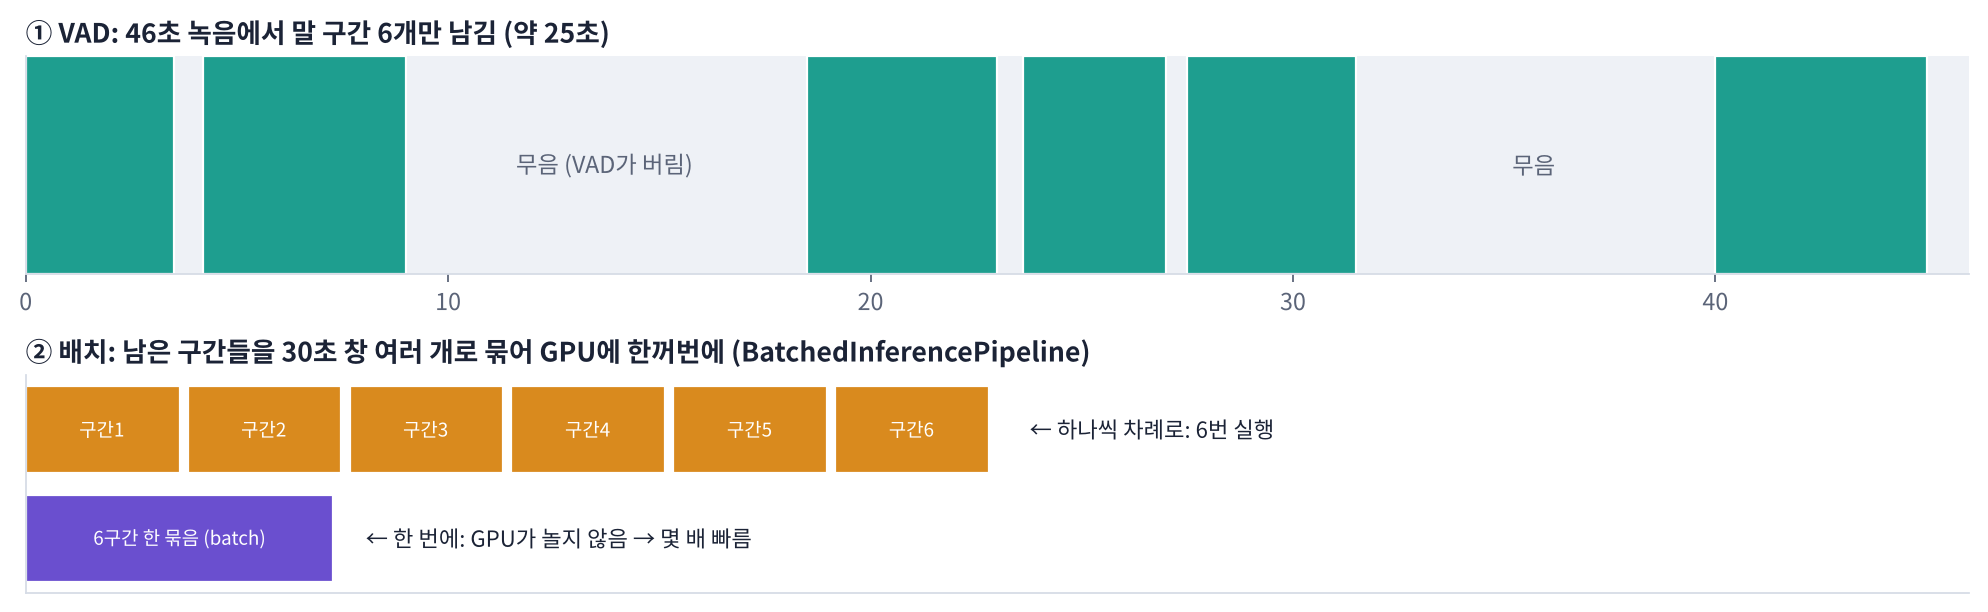

### 4-1. VAD: 무음은 계산하지 않는다

> 💬 **쉽게 말하면**: D7에서 환각을 막으려고 쓴 VAD가 **속도에도** 효과가 있습니다. 말이 없는 구간은 아예 Whisper에 넣지 않으니까요. faster-whisper는 `vad_filter=True` 한 줄로 Silero VAD를 켭니다.

👣 **한 단계씩 (`vad_filter=True`일 때 안에서 일어나는 일)**
1. Silero VAD가 말 구간을 찾음 (D4 · D7과 같은 모델)
2. 말 구간들을 이어 붙여 **무음이 빠진 짧은 음성**을 만듦
3. 그것만 받아 적고, 타임스탬프는 **원래 녹음의 시각으로 되돌려** 줌

> 🎬 **애니메이션 D8-5:** [VAD와 배치](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#batch) — VAD로 무음을 빼고, 남은 구간을 묶음 크기별로 처리할 때 걸리는 시간

### 🧩 빈칸 실습 5: VAD 켜기

In [ ]:
# 🧩 빈칸 실습 5
def fw_run(y, **kw):
    sync(); t0 = time.time()
    segs, info = fw.transcribe(y, language="ko", **kw)
    segs = list(segs); sync()
    return segs, info, time.time() - t0

segs_no, info_no, t_no = fw_run(lecture)
segs_vad, info_vad, t_vad = fw_run(lecture, vad_filter=____, vad_parameters=dict(min_silence_duration_ms=500))

for name, segs, info, t in [("VAD 없음", segs_no, info_no, t_no), ("VAD 켬", segs_vad, info_vad, t_vad)]:
    text = " ".join(s.text.strip() for s in segs)
    after = getattr(info, "duration_after_vad", None) or info.duration
    print(f"{name:7s} | 처리한 길이 {after:5.1f}초 / {info.duration:.1f}초 | {t:5.2f}초 | CER {jiwer.cer(norm(REF_LECTURE), norm(text)):6.1%}")
print("\nVAD 켬 구간 (원래 녹음 시각):")
for s in segs_vad:
    print(f"  [{s.start:6.2f} → {s.end:6.2f}] {s.text.strip()}")
check(info_vad.duration_after_vad < info_vad.duration, hint="True를 넣으면 VAD가 켜집니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
segs_vad, info_vad, t_vad = fw_run(lecture, vad_filter=True, vad_parameters=dict(min_silence_duration_ms=500))
```

**해설**: `info.duration_after_vad`가 원래 길이보다 짧아진 만큼 계산이 줄었습니다. 6초 무음과 문장 사이 쉼이 빠졌습니다. 구간 시각이 **원래 녹음 기준**으로 나오는 것도 확인하세요(VAD가 뺀 시간을 되돌려 줌). `min_silence_duration_ms`는 '이만큼 조용해야 끊는다'는 기준입니다. 너무 짧으면 문장 중간 쉼에서도 끊깁니다.

</details>

### 4-2. 배치: 짧은 구간들을 묶어서 한꺼번에

> 💬 **쉽게 말하면**: VAD로 자른 구간들을 하나씩 차례로 받아 적는 대신, **여러 개를 한 묶음(batch)으로** GPU에 넣습니다. GPU는 한 개를 계산하든 8개를 계산하든 시간이 크게 다르지 않아서, 묶을수록 이득입니다.

> 🍎 **비유: 엘리베이터**. 한 명씩 태워 올리면 8번 왕복, 8명을 한 번에 태우면 1번. 엘리베이터(GPU)가 충분히 크다면 묶어 태우는 게 압도적으로 빠릅니다. 단, 너무 많이 태우면 정원 초과(메모리 부족)입니다.

`BatchedInferencePipeline`이 하는 일:
1. VAD로 말 구간을 찾고, 30초를 넘지 않게 이어 붙여 **창 여러 개**를 만듦
2. 창 `batch_size`개를 한 묶음으로 Encoder · Decoder에 동시에 넣음
3. 결과를 시간 순서대로 이어 붙임

⚠️ 창끼리 독립적으로 받아 적으므로 D7의 '이전 문장 참고'는 쓰지 않습니다. 그래서 반복 고리 전염 걱정은 줄지만, 문맥이 끊기는 대가가 있습니다.

### 🧩 빈칸 실습 6: 묶음 크기 정하기
T4 GPU에서 small 모델에 무난한 묶음 크기 **8**을 넣으세요. 강의 녹음을 4번 이어 붙인 긴 녹음(약 3분)으로 비교합니다.

In [ ]:
# 🧩 빈칸 실습 6
from faster_whisper import BatchedInferencePipeline

BATCH = ____
long_rec = np.concatenate([lecture] * 4)                                # 약 3분짜리 녹음
batched = BatchedInferencePipeline(model=fw)

sync(); t0 = time.time()
seq_segs, seq_info = fw.transcribe(long_rec, language="ko", vad_filter=True); seq_segs = list(seq_segs)
sync(); t_seq = time.time() - t0
sync(); t0 = time.time()
bat_segs, bat_info = batched.transcribe(long_rec, language="ko", batch_size=BATCH); bat_segs = list(bat_segs)
sync(); t_bat = time.time() - t0

ref4 = " ".join([REF_LECTURE] * 4)
for name, segs, t in [("차례로 (VAD)", seq_segs, t_seq), (f"배치 {BATCH}개씩", bat_segs, t_bat)]:
    text = " ".join(s.text.strip() for s in segs)
    print(f"{name:12s} | {t:6.2f}초 | RTF {t / (len(long_rec) / SR):.3f} | 구간 {len(segs):2d}개 | CER {jiwer.cer(norm(ref4), norm(text)):6.1%}")
print(f"→ 배치가 {t_seq / max(t_bat, 1e-9):.1f}배 빠름" + ("" if DEVICE == "cuda" else " (CPU에서는 효과가 작습니다)"))
check(BATCH == 8, hint="묶음 크기 8을 넣습니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
BATCH = 8
```

**해설**: GPU에서는 보통 **2~4배 이상** 빨라집니다. CPU는 원래 한 번에 하나씩 계산하는 편이라 효과가 작습니다. 묶음 크기를 16, 32로 올리면 더 빨라지다가 어느 순간 **메모리 부족(CUDA out of memory)** 이 납니다. 서버에서 여러 사용자의 파일을 동시에 처리할 때(7주차 D33 GPU 서빙)도 같은 원리를 씁니다.

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day08/worksheet.html)** — 양자화의 뜻, float32 · float16 · int8 바이트 수, scale과 반올림, 양자화 오차, `compute_type` 선택(GPU float16 · CPU int8), int8이 항상 빠르지는 않음, `vad_filter`와 `duration_after_vad`, 배치의 원리와 메모리 한계
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 5. whisper.cpp: 파이썬 없이, GPU 없이

> 💬 **쉽게 말하면**: whisper.cpp는 Whisper를 **C/C++로 다시 짠 실행 파일**입니다. 파이썬도 PyTorch도 필요 없어서 노트북 · 라즈베리파이 · 휴대폰 · 자동차 기기 안에서 돌릴 수 있습니다. 오늘은 Colab의 **CPU만으로** 빌드하고 받아 적습니다.

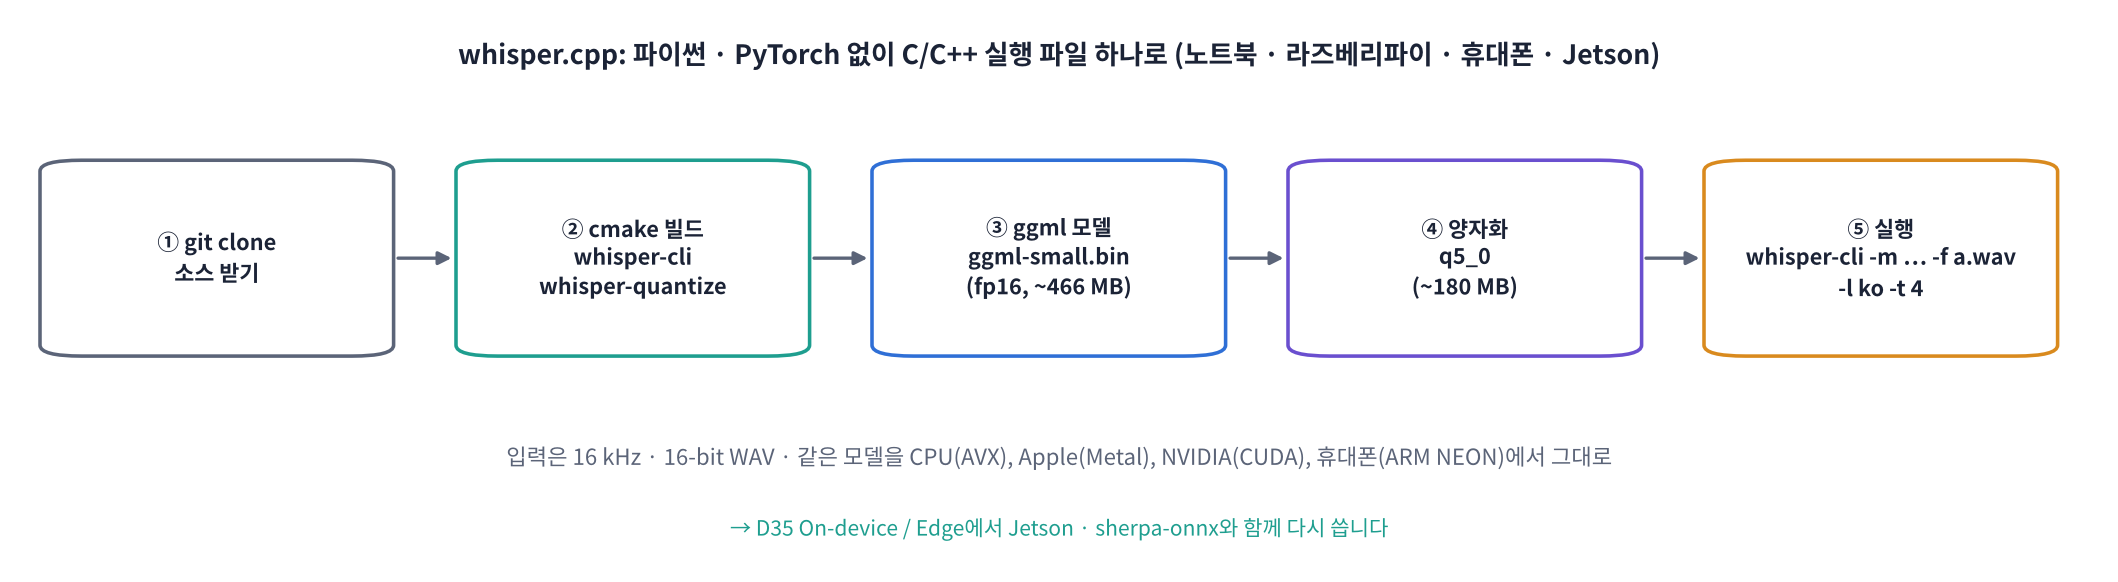

| | faster-whisper | whisper.cpp |
|---|---|---|
| 언어 | 파이썬 라이브러리 (속은 C++) | C/C++ 실행 파일 · 라이브러리 |
| 강점 | NVIDIA GPU 서버, 배치 처리 | **CPU · Apple Silicon · 임베디드**, 설치가 가벼움 |
| 모델 형식 | CTranslate2 폴더 | **ggml** 파일 하나 (`ggml-small.bin`) |
| 양자화 | float16 · int8 | **q8_0 · q5_0 · q4_0** 등 4~8비트 |
| 쓰는 곳 | 클라우드 API 서버 (D31 · D33) | 기기 안 받아쓰기 (D35 Edge) |

> 🍎 **비유: 통역사를 부르는 두 방법**. faster-whisper는 큰 사무실(GPU 서버)에 상주하는 통역팀, whisper.cpp는 **가방 하나로 어디든 출장 가는 통역사**입니다. 짐(설치)이 가볍고 전기(GPU)가 없어도 일합니다.

> 🎬 **애니메이션 D8-6:** [whisper.cpp 길잡이](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#wcpp) — 빌드 → 모델 → 양자화 → 실행 단계와 양자화 형식별 크기

### 5-1. 소스 받기와 빌드 (약 2~4분)
`cmake`로 C++ 소스를 컴파일해 실행 파일을 만듭니다. 오늘은 GPU(CUDA) 옵션 없이 **CPU용**으로 빌드합니다. 빌드 로그는 `build.log`에 저장합니다.

In [ ]:
!git clone --depth 1 https://github.com/ggml-org/whisper.cpp
!cmake -S whisper.cpp -B whisper.cpp/build -DCMAKE_BUILD_TYPE=Release > build.log 2>&1
!cmake --build whisper.cpp/build -j --config Release >> build.log 2>&1
!ls whisper.cpp/build/bin | grep -E "whisper-(cli|quantize)|^quantize$" 

In [ ]:
# 실행 파일 경로 정하기 (버전에 따라 quantize 이름이 다름: whisper-quantize 또는 quantize)
BIN = "whisper.cpp/build/bin"
CLI = f"{BIN}/whisper-cli"
QUANT_BIN = next((f"{BIN}/{n}" for n in ["whisper-quantize", "quantize"] if os.path.exists(f"{BIN}/{n}")), None)
MODELS = "whisper.cpp/models"
print("whisper-cli:", os.path.exists(CLI), "| quantize:", QUANT_BIN)

### 5-2. ggml 모델 받기
whisper.cpp 저장소에 들어 있는 스크립트로 **ggml 형식** small 모델(float16, 약 466 MB)을 받습니다.

In [ ]:
!bash whisper.cpp/models/download-ggml-model.sh small whisper.cpp/models
!ls -la whisper.cpp/models/*.bin | grep -v for-tests

### 🧩 빈칸 실습 7: q5_0으로 양자화하기
`whisper-quantize 입력.bin 출력.bin 형식` 순서로 실행합니다. 형식 이름에 **5비트 형식 `"q5_0"`** 을 넣으세요.

| 형식 | 숫자 하나당 (대략) | small 파일 크기 (대략) | 언제 |
|---|---|---|---|
| f16 (원본) | 16비트 | 466 MB | 기준 |
| q8_0 | 8.5비트 | 250 MB | 정확도 최우선 |
| **q5_0** | 5.5비트 | **180 MB** | **크기 · 정확도 균형 (whisper.cpp 문서의 예시)** |
| q4_0 | 4.5비트 | 150 MB | 메모리가 아주 적은 기기 |

(블록마다 눈금 간격(scale)을 따로 저장하기 때문에 '5비트'인데 실제로는 5.5비트쯤 씁니다.)

In [ ]:
# 🧩 빈칸 실습 7
QTYPE = ____

src = f"{MODELS}/ggml-small.bin"
dst = f"{MODELS}/ggml-small-{QTYPE}.bin"
t0 = time.time()
r = subprocess.run([QUANT_BIN, src, dst, QTYPE], capture_output=True, text=True)
print(f"양자화 {time.time() - t0:.1f}초, 성공 = {r.returncode == 0}")
for p in [src, dst]:
    print(f"  {os.path.basename(p):24s} {os.path.getsize(p) / 1e6:7.1f} MB")
check(r.returncode == 0 and os.path.getsize(dst) < 0.5 * os.path.getsize(src), hint='5비트 형식 이름은 "q5_0" 입니다 (따옴표 포함).')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
QTYPE = "q5_0"
```

**해설**: 파일이 원래의 **40% 안팎**으로 줄어듭니다. f16(16비트) → q5_0(약 5.5비트)이니 계산과 맞습니다. 모든 층을 양자화하지는 않습니다(위치 임베딩 · 정규화 층 같은 작은 텐서는 그대로). 양자화는 **한 번만** 해 두면 되고, 만든 파일을 기기에 복사해서 씁니다.

</details>

### 5-3. whisper-cli로 받아 적기: f16 vs q5_0
whisper-cli는 **16 kHz · 16-bit WAV**만 받습니다. 짧은 이야기 음성을 WAV로 저장하고, 두 모델로 받아 적어 시간 · 크기 · 정확도를 비교합니다.

| 옵션 | 뜻 |
|---|---|
| `-m 모델` / `-f 파일` | 모델 파일, 입력 WAV |
| `-l ko` | 언어 (기본값은 영어 `en`이라 **꼭 지정**. D7의 언어 고정과 같은 이유) |
| `-t N` | CPU 스레드 수 |
| `-nt` | 출력에 시각 표시 안 함 |
| `-otxt -of 이름` | 결과를 `이름.txt`로 저장 |

In [ ]:
sf.write("story.wav", story, SR, subtype="PCM_16")                    # 16-bit WAV로 저장
THREADS = os.cpu_count()

def run_cpp(model_path, wav="story.wav", lang="ko"):
    out = "cpp_out"
    t0 = time.time()
    r = subprocess.run([CLI, "-m", model_path, "-f", wav, "-l", lang, "-t", str(THREADS), "-nt", "-otxt", "-of", out],
                       capture_output=True, text=True)
    t = time.time() - t0
    text = open(out + ".txt", encoding="utf-8").read().strip() if os.path.exists(out + ".txt") else ""
    if r.returncode != 0: print(r.stderr[-500:])
    return text, t

cpp_rows = []
for p in [src, dst]:
    text, t = run_cpp(p)
    cer = jiwer.cer(norm(REF_STORY), norm(text))
    cpp_rows.append((os.path.basename(p), os.path.getsize(p) / 1e6, t, cer))
    print(f"{os.path.basename(p):24s} | {os.path.getsize(p) / 1e6:6.0f} MB | {t:6.2f}초 (CPU {THREADS}스레드) | RTF {t / (len(story) / SR):.2f} | CER {cer:6.1%}")
    print(f"   {text[:90]}")

#### 🔍 코드 해설과 결과 읽기

| 코드 | 하는 일 |
|---|---|
| `sf.write(..., subtype="PCM_16")` | 16-bit 정수 WAV로 저장. float WAV나 mp3는 whisper-cli가 바로 못 읽음 (ffmpeg로 변환 필요) |
| `subprocess.run([...], capture_output=True)` | 파이썬에서 실행 파일을 부르고, 화면 출력을 받아 옴 |
| `-t THREADS` | CPU 코어를 모두 사용. Colab 무료는 2코어라 느린 편 |

**결과 읽기**: Colab CPU(2코어)에서는 RTF가 1 근처이거나 그보다 클 수 있습니다. 실망하지 마세요. **Apple M 시리즈 맥북이나 8코어 PC**에서는 같은 명령이 몇 배 빠르고, Metal(Apple GPU)이나 CUDA로 빌드하면 더 빨라집니다. 중요한 것은 **q5_0이 파일은 40%인데 CER은 거의 같다**는 점입니다.

**❓ 생각해 보기**: 공장 현장에서 인터넷 없이 태블릿(ARM CPU, 메모리 4 GB)으로 안전 점검 음성을 받아 적어야 합니다. 오늘 배운 것 중 무엇을 고르겠습니까?

<details>
<summary>답 보기</summary>

**whisper.cpp + small(또는 base) q5_0 모델**입니다. 파이썬 · GPU 없이 실행 파일과 180 MB 파일 하나면 됩니다. 언어는 `-l ko`로 고정하고, D7처럼 **VAD**(`--vad` 옵션 + VAD 모델)로 무음을 빼면 속도와 환각 모두 좋아집니다. 고유명사가 많으면 `--prompt`로 용어 쪽지를 줍니다. D35에서 Jetson · sherpa-onnx와 함께 다시 다룹니다.

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day08/worksheet.html)** — whisper.cpp의 특징과 쓰임(Edge), faster-whisper와 비교, cmake 빌드, ggml 형식, q8_0 · q5_0 · q4_0, 블록마다 scale, 양자화 순서, whisper-cli 옵션(-m -f -l -t), 16-bit WAV, `-l ko`를 빼면?
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 6. 스트리밍 인식: 말하는 도중에 자막 띄우기

> 💬 **쉽게 말하면**: 지금까지는 **녹음 파일을 다 받은 뒤** 처리했습니다. 스트리밍은 마이크 소리가 **조금씩 들어오는 동안** 받아 적어 화면에 띄우는 것입니다. Whisper는 원래 30초 창 단위 모델이라 스트리밍용이 아닙니다. 그래서 **잘라서 넣는 요령**이 필요합니다.

### 6-1. 스트리밍의 지표는 '지연(latency)'

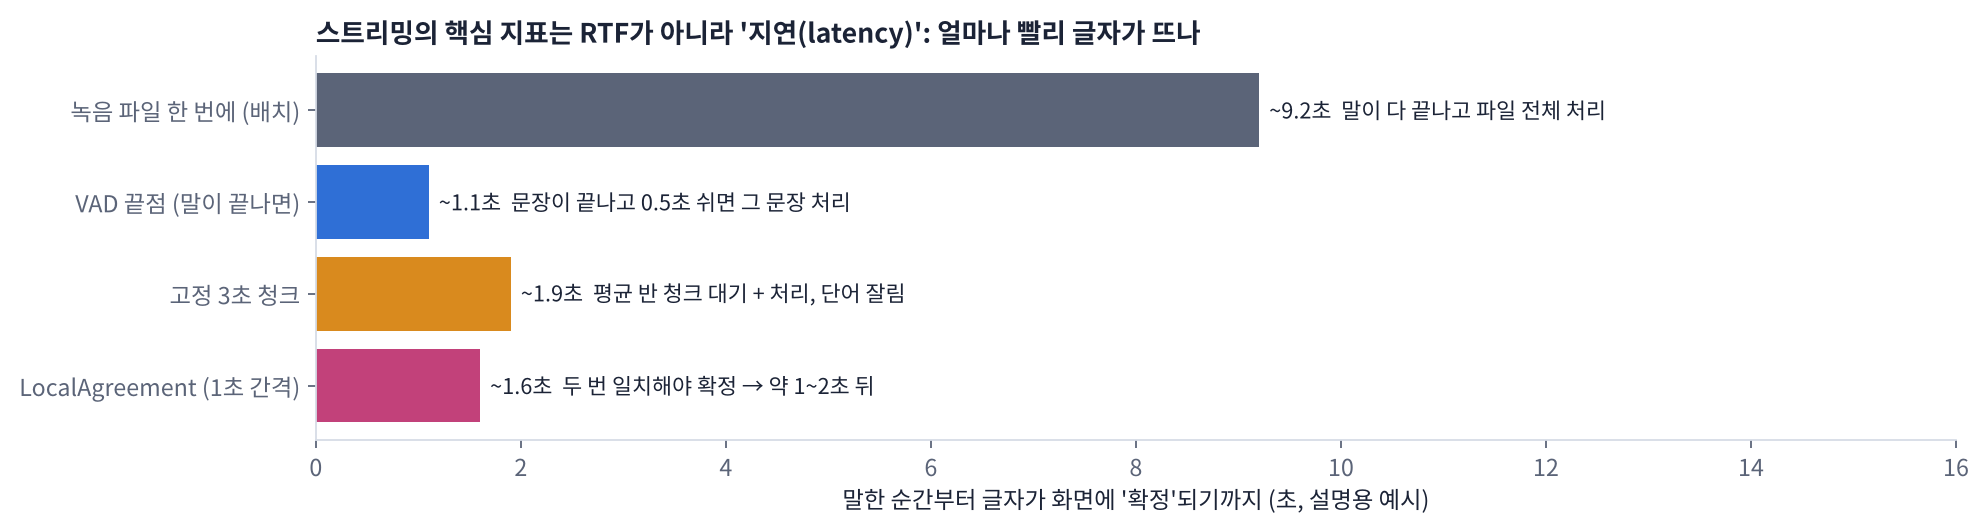

| 지표 | 질문 | 오늘까지 |
|---|---|---|
| RTF | 1초 음성을 몇 초에 처리하나? | 배치 처리의 지표 (Part 1~5) |
| **지연(latency)** | 말한 순간부터 **글자가 화면에 확정되기까지** 몇 초? | **스트리밍의 지표** (Part 6) |

RTF가 1보다 작아야 하는 것은 기본 조건이고(밀리지 않으려면), 사용자가 느끼는 것은 **지연**입니다. 음성 비서(5 · 6주차)는 사람 대화처럼 **1초 안쪽**을 목표로 합니다.

> 🍎 **비유: 동시통역 vs 순차통역**. 순차통역(배치)은 연사가 말을 다 끝낸 뒤 통역하니 정확하지만 기다려야 합니다. 동시통역(스트리밍)은 몇 초 뒤를 따라가며 바로 말하지만, 문장이 끝나기 전에 말을 시작하니 **나중에 고쳐 말하기도** 합니다. 오늘 만들 LocalAgreement가 바로 '언제 확정하고 언제 기다릴지'를 정하는 규칙입니다.

### 6-2. 가장 쉬운 방법: 고정 길이로 자르기 (그리고 그 문제)

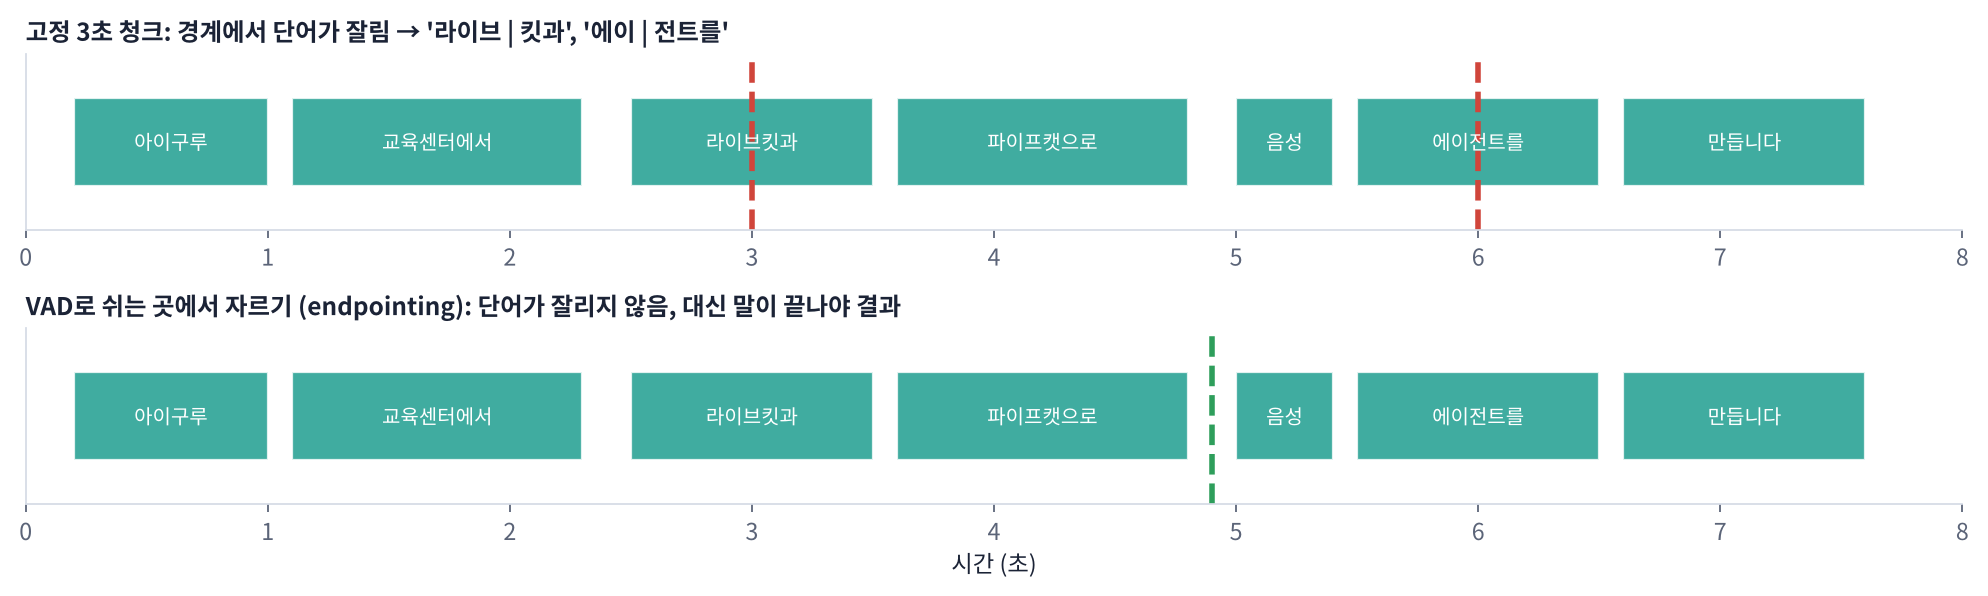

마이크에서 3초씩 받아 그때마다 받아 적으면 간단합니다. 하지만 **청크 경계에 걸친 단어가 잘립니다.** 아래에서 직접 확인합니다.

> 🎬 **애니메이션 D8-7:** [고정 청크 vs 끝점](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#chunk) — 청크 길이를 바꿔 잘리는 단어 수와 지연이 어떻게 바뀌는지

### 🧩 빈칸 실습 8: 3초씩 자르기
`range(시작, 끝, 간격)`의 **간격**에 청크 샘플 수를 넣어 겹치지 않게 자르세요.

In [ ]:
# 🧩 빈칸 실습 8
CHUNK_SEC = 3.0
CHUNK_N = int(CHUNK_SEC * SR)
chunks = [story[i:i + CHUNK_N] for i in range(0, len(story), ____)]

pieces = []
for k, ch in enumerate(chunks):
    text = " ".join(s.text.strip() for s in fw.transcribe(ch, language="ko", beam_size=1)[0])
    pieces.append(text)
    print(f"청크 {k + 1} [{k * CHUNK_SEC:4.1f}~{min((k + 1) * CHUNK_SEC, len(story) / SR):4.1f}초] {text}")
chunk_text = " ".join(pieces)
whole_text = " ".join(s.text.strip() for s in fw.transcribe(story, language="ko", beam_size=1)[0])
print(f"\n통째로 받아쓰기 CER {jiwer.cer(norm(REF_STORY), norm(whole_text)):6.1%} | {whole_text}")
print(f"3초 청크 이어 붙이기 CER {jiwer.cer(norm(REF_STORY), norm(chunk_text)):6.1%} | {chunk_text}")
check(sum(len(c) for c in chunks) == len(story) and len(chunks) == int(np.ceil(len(story) / CHUNK_N)),
      hint="청크끼리 겹치지 않으려면 간격도 CHUNK_N 이어야 합니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
chunks = [story[i:i + CHUNK_N] for i in range(0, len(story), CHUNK_N)]
```

**해설**: 대개 3초 청크 쪽 CER이 더 나쁩니다. 경계에서 '라이브 | 킷과'처럼 단어가 반쪽씩 나뉘어 각 청크가 엉뚱하게 받아 적거나, 짧은 소리 조각에서 환각이 생기기 때문입니다. 청크를 길게 하면 덜 잘리지만 **그만큼 지연이 늘어납니다**(3초 청크면 평균 1.5초 기다린 뒤 처리 시작). 이 딜레마를 푸는 방법이 다음 절입니다.

</details>

### 6-3. LocalAgreement: 두 번 같은 말이 나오면 확정

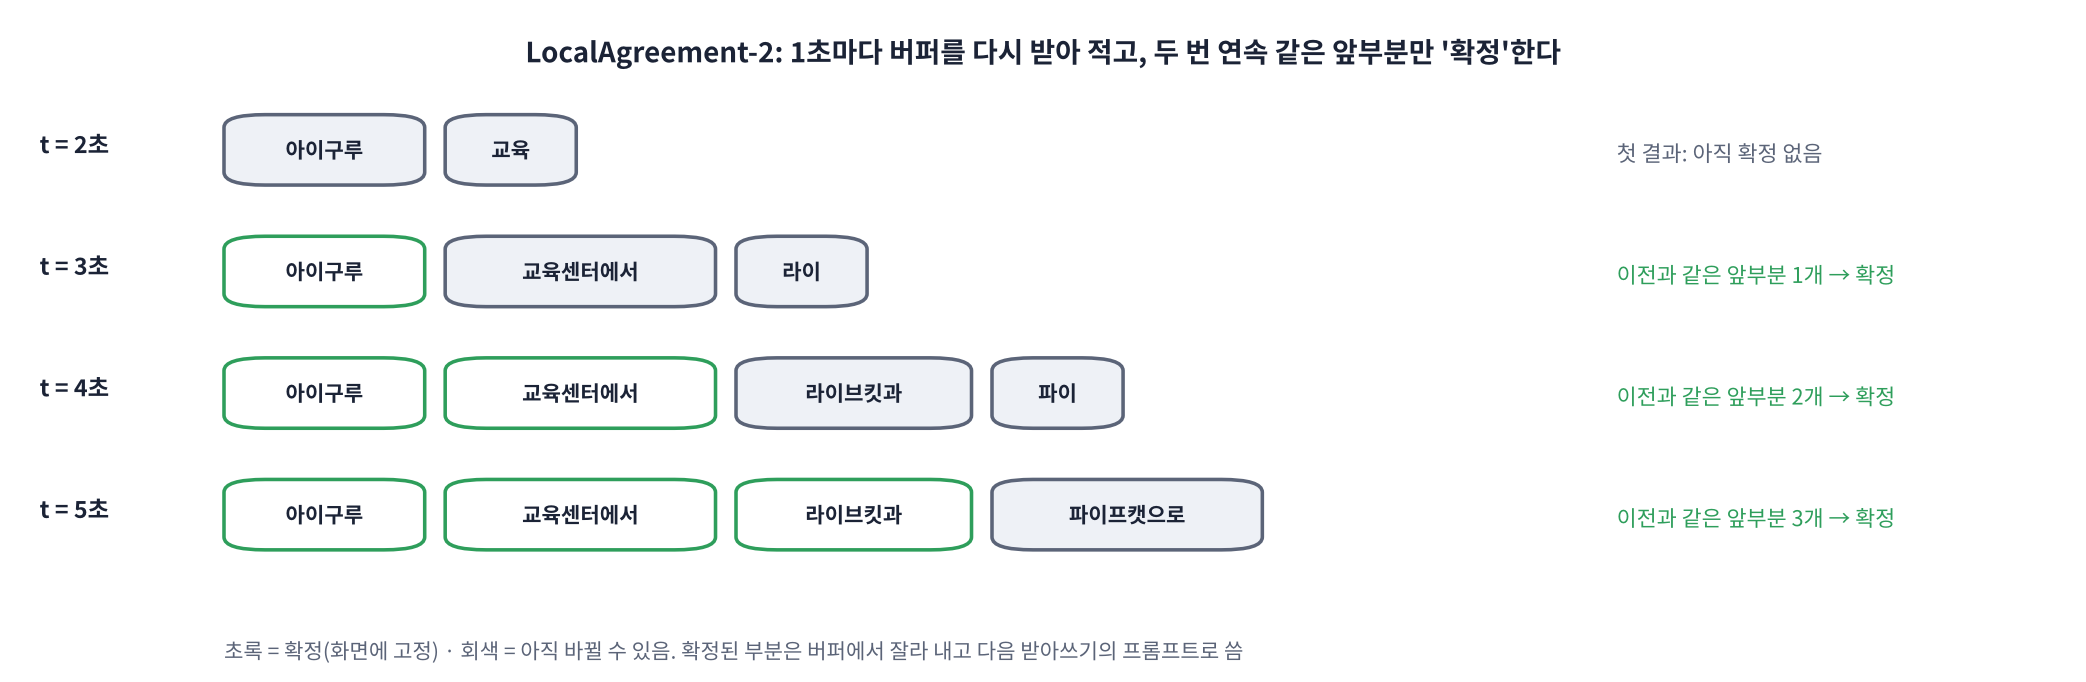

> 💬 **쉽게 말하면**: 1초마다 **지금까지 쌓인 소리 전체(버퍼)** 를 다시 받아 적습니다. 그리고 **이번 결과와 지난 결과가 앞에서부터 똑같은 단어들만 '확정'** 해서 화면에 고정합니다. 뒤쪽 바뀔 수 있는 단어는 회색으로 두고 다음 결과를 기다립니다.

👣 **한 단계씩** (ÚFAL `whisper_streaming`의 LocalAgreement-2 방식을 단순화)
1. 새 소리 1초가 들어오면 버퍼(아직 확정 안 된 부분의 소리)에 붙임
2. 버퍼 전체를 받아 적어 단어 목록(가설)을 만듦 (단어마다 시작 · 끝 시각 포함)
3. **이번 가설과 지난 가설의 공통 앞부분**(longest common prefix)을 찾아 그 단어들을 확정
4. 확정된 단어는 다음 받아쓰기의 **프롬프트**(D7)로 넘겨 문맥을 잇고, 버퍼가 길어지면 확정된 곳까지 잘라 냄
5. 녹음이 끝나면 남은 단어를 모두 확정

**왜 두 번일까?** 한 번만 나온 단어는 **소리가 덜 들어와서** 틀렸을 수 있습니다('파이' → 1초 뒤 '파이프캣으로'). 1초 더 들은 뒤에도 같다면 믿을 만합니다. 대가는 **약 1~2초의 지연**입니다.

> 🍎 **비유: 증인 두 명**. 한 사람 말만 듣고 기록하면 나중에 고칠 일이 생깁니다. 두 증인(연속된 두 번의 받아쓰기)이 **같은 말을 한 부분까지만** 기록부에 올립니다.

> 🎬 **애니메이션 D8-8:** [LocalAgreement](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#agree) — 1초씩 진행하며 가설이 바뀌고 확정 부분이 늘어나는 과정

### 🧩 빈칸 실습 9: 공통 앞부분 길이 (LocalAgreement의 핵심)
두 단어 목록 `a`, `b`를 앞에서부터 비교해 **같은 동안** 개수를 셉니다. `a[i]`와 무엇을 비교해야 할까요?

In [ ]:
# 🧩 빈칸 실습 9
def lcp(a, b):
    # longest common prefix: 앞에서부터 같은 단어가 몇 개 이어지나
    i = 0
    while i < min(len(a), len(b)) and a[i] == ____[i]:
        i += 1
    return i

tests = [(["아이구루", "교육"], ["아이구루", "교육센터에서", "라이"], 1),
         (["아이구루", "교육센터에서", "라이"], ["아이구루", "교육센터에서", "라이브킷과", "파이"], 2),
         (["가", "나"], ["다", "나"], 0), ([], ["가"], 0)]
for a, b, want in tests:
    print(f"{str(a):34s} vs {str(b):48s} → {lcp(a, b)} {'✅' if lcp(a, b) == want else '❌'}")
check(all(lcp(a, b) == want for a, b, want in tests), hint="같은 위치 i의 b 단어와 비교합니다: b[i]")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
while i < min(len(a), len(b)) and a[i] == b[i]:
```

**해설**: 두 목록을 같은 위치끼리 비교하다가 **처음 다른 곳에서 멈춥니다.** 그 앞까지가 '두 증인이 같은 말을 한 부분'입니다. 실제 구현에서는 '교육센터에서.'와 '교육센터에서'처럼 문장 부호만 다른 경우도 같은 단어로 보도록 `norm()`을 거쳐 비교합니다(아래 셀).

</details>

In [ ]:
# ▶️ 스트리밍 시뮬레이션: 마이크처럼 1초씩 소리를 넣으며 LocalAgreement로 확정하기
def stream_local_agreement(y, step=1.0, max_buf=12.0, verbose=True):
    total = len(y) / SR
    committed = []                    # 확정 단어: (단어, 시작, 끝, 확정된 시각)
    prev = []                         # 지난 가설 중 아직 확정 안 된 단어들: (단어, 시작, 끝)
    buf_start, t, logs = 0.0, step, []
    while True:
        now = min(t, total)
        buf = y[int(buf_start * SR): int(now * SR)]
        prompt = " ".join(w for w, *_ in committed[-30:]) or None
        t0 = time.time()
        segs, _ = fw.transcribe(buf, language="ko", beam_size=1, word_timestamps=True,
                                condition_on_previous_text=False, initial_prompt=prompt, max_new_tokens=128)
        words = [(w.word.strip(), buf_start + w.start, buf_start + w.end) for s in segs for w in (s.words or [])]
        compute = time.time() - t0
        last_end = committed[-1][2] if committed else 0.0
        words = [w for w in words if w[1] >= last_end - 0.1 and w[0]]          # 이미 확정된 시각 이전은 버림
        n = lcp([norm(w[0]) for w in prev], [norm(w[0]) for w in words])
        new = [(w, s, e, now) for w, s, e in words[:n]]
        committed += new
        prev = words[n:]
        logs.append(dict(t=now, compute=compute, n_new=len(new), pending=" ".join(w for w, *_ in prev)))
        if verbose:
            done = " ".join(w for w, *_ in committed)
            print(f"t={now:5.1f}s ({compute:4.2f}s 계산) ✔ {done[-45:]:45s} | … {logs[-1]['pending'][:30]}")
        if committed and now - buf_start > max_buf:
            buf_start = committed[-1][2]                                        # 버퍼를 확정 지점까지 잘라 냄
        if now >= total:
            committed += [(w, s, e, now) for w, s, e in prev]                   # 끝: 남은 단어 확정 (flush)
            break
        t += step
    return committed, logs

committed, logs = stream_local_agreement(story)
stream_text = " ".join(w for w, *_ in committed)
print(f"\n스트리밍 결과 CER {jiwer.cer(norm(REF_STORY), norm(stream_text)):6.1%} | {stream_text}")

### 6-4. 지연과 실시간 여부 재기

두 가지를 봅니다.
1. **단어별 지연** = 단어가 **확정된 시각** − 그 단어를 **다 말한 시각**(단어 끝 시각)
2. **실시간 가능 여부** = 1초마다 받아 적는 데 걸린 계산 시간이 **1초보다 짧은가** (길면 점점 밀림)

In [ ]:
# ▶️ 지연과 계산 시간
lat = np.array([ct - e for _, s, e, ct in committed])
comp = np.array([l["compute"] for l in logs])
print(f"확정 단어 {len(committed)}개 | 지연 평균 {lat.mean():.2f}초, 중앙값 {np.median(lat):.2f}초, 최대 {lat.max():.2f}초")
print(f"1초마다 계산 시간: 평균 {comp.mean():.2f}초, 최대 {comp.max():.2f}초 → " + ("✅ 실시간 가능 (1초 안에 끝남)" if comp.max() < 1.0 else "⚠️ 1초를 넘는 순간이 있음 → 더 작은 모델 · int8 · GPU 필요"))

fig, axs = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
axs[0].plot(np.arange(len(story)) / SR, story, lw=0.3, color="tab:cyan")
for w, s, e, ct in committed:
    axs[0].axvspan(s, e, color="tab:green", alpha=0.15)
axs[0].set_title("words in the audio (green = word span)")
for i, (w, s, e, ct) in enumerate(committed):
    axs[1].plot([e, ct], [i, i], color="tab:pink", lw=2); axs[1].plot(e, i, "o", color="tab:green", ms=4); axs[1].plot(ct, i, "s", color="tab:pink", ms=4)
axs[1].set_ylabel("word #"); axs[1].set_xlabel("time (s)"); axs[1].set_title("latency per word: word end (o) -> committed on screen (s)")
plt.tight_layout(); plt.show()

**결과 읽기**: 지연은 보통 **1~2초** 안팎입니다(1초 간격 + 두 번 일치 + 계산 시간). 줄이려면:

| 손잡이 | 효과 | 대가 |
|---|---|---|
| 간격(step)을 0.5초로 | 더 자주 확정 → 지연 ↓ | 계산 2배 → 실시간이 깨질 수 있음 |
| 더 작은 모델 · int8 · GPU | 계산 시간 ↓ | 정확도 ↓ (모델을 줄이면) |
| 버퍼 최대 길이를 짧게 | 계산 시간 ↓ | 문맥 ↓ |
| VAD 끝점 함께 쓰기 | 말이 끝나면 즉시 전부 확정 | 끝점 판단 지연(0.3~0.8초) |

실제 서비스에서는 이 받아쓰기 부분이 **Pipecat · LiveKit**(6주차) 안에 들어가고, 마이크 소리는 **WebRTC**(D26)로 들어옵니다. 오늘 만든 시뮬레이션이 그 속에서 일어나는 일입니다.

**❓ 생각해 보기**: 사람과 대화하는 음성 비서라면, 단어 하나하나를 빨리 띄우는 LocalAgreement와 '말이 끝나면 한 번에' 받아 적는 VAD 끝점 방식 중 무엇이 더 중요할까요?

<details>
<summary>답 보기</summary>

음성 비서는 **사용자의 말이 끝났는지(turn)** 를 알아야 LLM에 넘길 수 있습니다. 그래서 **VAD 끝점(endpointing)** 이 핵심이고, 단어별 실시간 자막은 화면 표시용 덤입니다. 반대로 회의 실시간 자막이나 방송 자막은 **LocalAgreement처럼 단어가 계속 흘러나오는 방식**이 중요합니다. D28(Pipecat Turn Detection)에서 두 가지를 함께 씁니다.

</details>

> 🎬 **애니메이션 D8-9:** [지연 비교](https://imguru-mooc.github.io/AI_Voice/day08/animation.html#latency) — 방식별로 말한 순간부터 글자가 확정되기까지의 타임라인

---
### 📝 4교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day08/worksheet.html)** — 배치 vs 스트리밍, RTF vs 지연, 고정 청크의 단어 잘림, 청크 길이와 지연의 교환, LocalAgreement 순서, 공통 앞부분(lcp), 확정 단어를 프롬프트로, 버퍼 자르기, 단어별 지연 계산, 실시간 조건(계산 < 간격), VAD 끝점
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 4교시까지 마쳤다면 아래 Part 7의 **제출 방법**을 따라 노션에 제출하세요.

## Part 7. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| 병목 재기 | 패딩 · Decoder 반복 · 큰 숫자 · 파이썬 오버헤드 | `dec_time = total - enc_time` |
| faster-whisper | 같은 가중치, CTranslate2 C++ 엔진 → 최대 약 4배 | `WhisperModel("small", compute_type=...)` |
| 게으른 생성기 | 꺼낼 때 계산. 시간은 `list()`까지 재기 | `segs = list(segments)` |
| 양자화 | scale로 나눠 반올림 → int8 | `q = round(w / scale)` |
| compute_type | GPU float16, CPU int8, 직접 재 보기 | `"float16"`, `"int8"`, `"int8_float16"` |
| VAD | 무음은 계산 안 함, 시각은 원래 녹음 기준 | `vad_filter=True` |
| 배치 | 구간 여러 개를 GPU에 한꺼번에 | `BatchedInferencePipeline(...).transcribe(batch_size=8)` |
| whisper.cpp | C++ 실행 파일, ggml 모델, CPU · Edge | `whisper-cli -m … -f a.wav -l ko -t 4` |
| ggml 양자화 | q5_0 = 크기 40%, 정확도 거의 그대로 | `whisper-quantize in.bin out.bin q5_0` |
| 스트리밍 지표 | RTF < 1은 기본, 사용자는 **지연**을 느낌 | 확정 시각 − 단어 끝 시각 |
| 고정 청크 | 간단하지만 경계에서 단어가 잘림 | `range(0, len(y), CHUNK_N)` |
| LocalAgreement | 두 번 연속 같은 앞부분만 확정 | `lcp(prev, words)` |

### 📝 과제
1. **내 PC에서 whisper.cpp**: 집이나 회사 PC(또는 맥북)에 whisper.cpp를 빌드하고, 내 목소리 1분 녹음을 `ggml-small.bin`과 `ggml-small-q5_0.bin`으로 받아 적어 시간 · 파일 크기 · CER을 표로 정리하세요. CPU 종류와 코어 수도 적습니다.
2. **최적화 표 만들기**: 오늘 노트북의 강의 녹음(또는 내 녹음 3분)으로 ① transformers float32 ② faster-whisper float16 ③ int8 ④ + VAD ⑤ + 배치 8의 RTF와 CER을 한 표로 만들고, 가장 효과가 컸던 단계와 그 이유를 두세 문장으로 쓰세요.
3. **스트리밍 손잡이 실험**: `stream_local_agreement()`의 `step`을 0.5 / 1.0 / 2.0초로 바꿔 평균 지연 · 최대 계산 시간 · CER을 비교하고, 음성 비서에 쓸 값을 하나 골라 이유를 쓰세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D8 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day08/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. 이름, 교시별 점수, 오답 표(내 답과 정답)가 함께 붙습니다.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day08/animation.html) — D8-1 ~ D8-9

### 다음 시간 (D9)
오늘 스트리밍에서 **단어별 시각**(`word_timestamps=True`)을 썼습니다. Whisper의 단어 시각은 cross-attention을 이용한 추정이라 ±수백 ms 흔들립니다. D9에서는 D6의 **CTC 정렬**로 단어 시각을 정확히 맞추는 **WhisperX**, 그리고 "누가 말했나"를 구분하는 **pyannote 화자 분리(Speaker Diarization)** 를 배웁니다. D10 회의록 생성기의 핵심 부품입니다.